<a href="https://colab.research.google.com/github/vinayak932/Bloging_site/blob/master/mall_customer_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [5]:
df = pd.read_csv("Mall_Customers.csv")


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
df.shape

(200, 5)

In [8]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [9]:
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


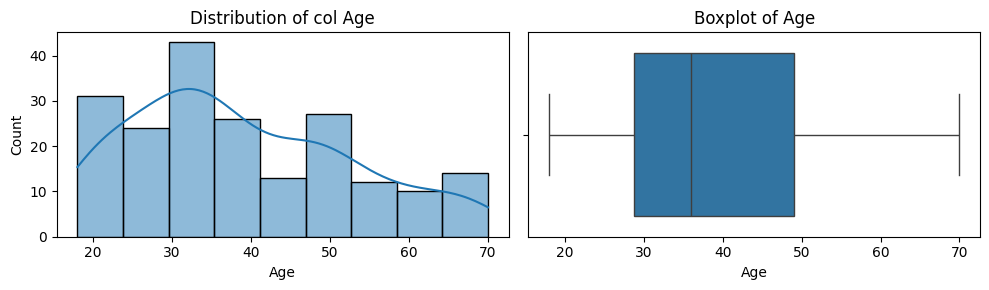

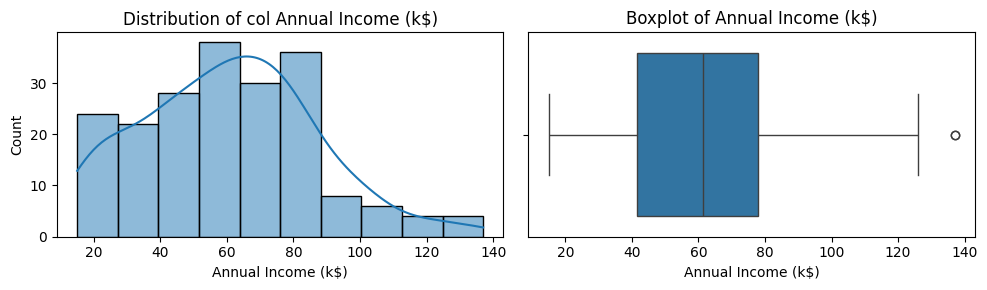

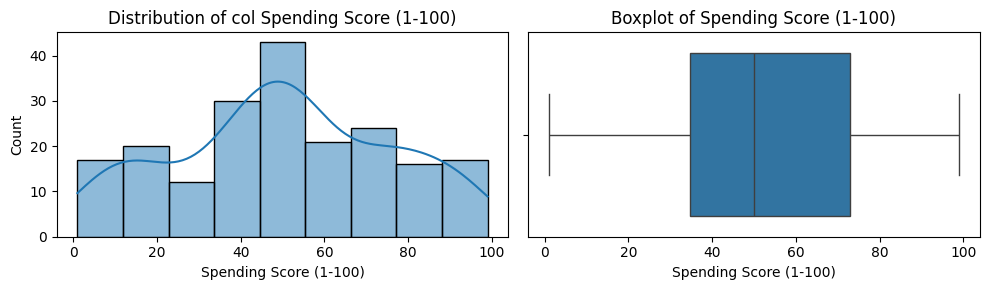

In [10]:
import seaborn as sns
columns = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]
for col in columns:
  fig, axes = plt.subplots(1,2, figsize=(10,3))
  sns.histplot(data=df, x=col, kde=True, ax=axes[0])
  axes[0].set_title(f"Distribution of col {col}")
  sns.boxplot(data=df, x=col, ax=axes[1])
  axes[1].set_title(f"Boxplot of {col}")
  plt.tight_layout()
  plt.show()

In [11]:
for col in columns:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1

  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr

  print(f"\n{col}")
  print(df[col].skew(), 2)
  print("IQR:", round(iqr, 2))
  print("Potential Outliers:", ((df[col] < lower) | (df[col] > upper)).sum())


Age
0.48556885096681657 2
IQR: 20.25
Potential Outliers: 0

Annual Income (k$)
0.3218425498619055 2
IQR: 36.5
Potential Outliers: 2

Spending Score (1-100)
-0.047220201374263374 2
IQR: 38.25
Potential Outliers: 0


In [12]:
col = "Annual Income (k$)"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (df[col] < lower) | (df[col] > upper)

outliers = df.loc[mask]

print(outliers)

     CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
198         199   Male   32                 137                      18
199         200   Male   30                 137                      83


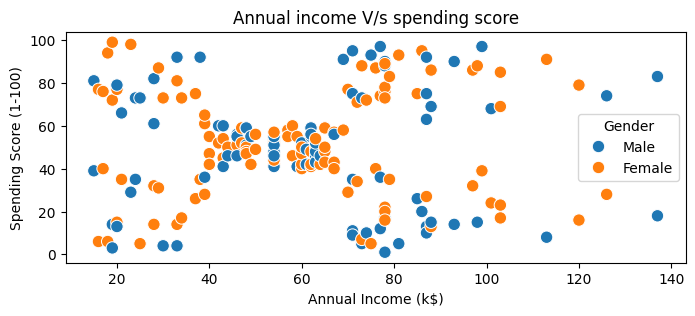

In [13]:
plt.figure(figsize=(8,3))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Gender", s=80)
plt.title("Annual income V/s spending score")
plt.show()

In [14]:
print(df[["Annual Income (k$)",
          "Spending Score (1-100)"]].corr())

                        Annual Income (k$)  Spending Score (1-100)
Annual Income (k$)                1.000000                0.009903
Spending Score (1-100)            0.009903                1.000000


In [15]:
print(df.groupby("Gender")["Spending Score (1-100)"].agg(["mean","median","std","count"]).round(2))

         mean  median    std  count
Gender                             
Female  51.53    50.0  24.11    112
Male    48.51    50.0  27.90     88


In [16]:
numeric_df = df[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
]

print(numeric_df.corr().round(3))

                          Age  Annual Income (k$)  Spending Score (1-100)
Age                     1.000              -0.012                  -0.327
Annual Income (k$)     -0.012               1.000                   0.010
Spending Score (1-100) -0.327               0.010                   1.000


In [17]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)

print(X.shape)
print(x_scaled.shape)
print(x_scaled.mean(axis=0))
print(x_scaled.std(axis=0))

(200, 2)
(200, 2)
[-2.13162821e-16 -1.46549439e-16]
[1. 1.]


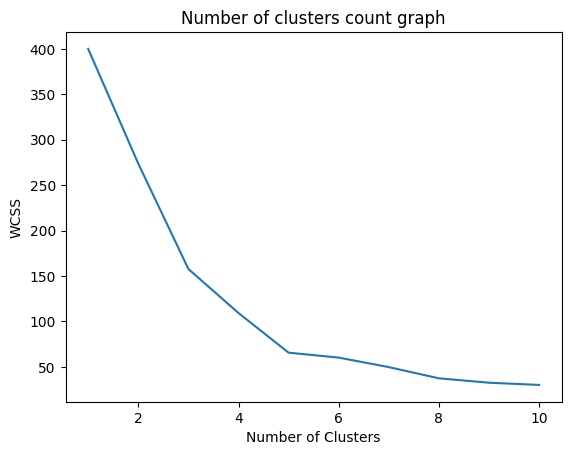

In [19]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1,11):
   kmean = KMeans(n_clusters=i, init="k-means++", random_state=42)
   kmean.fit(x_scaled)
   wcss.append(kmean.inertia_)
plt.plot(range(1,11), wcss)
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Number of clusters count graph")
plt.show()

In [25]:
k_mean_model = KMeans(n_clusters = 5, init="k-means++", random_state= 42)
labels = k_mean_model.fit_predict(x_scaled)

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(x_scaled)
    score = silhouette_score(x_scaled, labels)

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.321
K = 3, Silhouette Score = 0.467
K = 4, Silhouette Score = 0.494
K = 5, Silhouette Score = 0.555
K = 6, Silhouette Score = 0.540
K = 7, Silhouette Score = 0.528
K = 8, Silhouette Score = 0.455
K = 9, Silhouette Score = 0.457
K = 10, Silhouette Score = 0.443


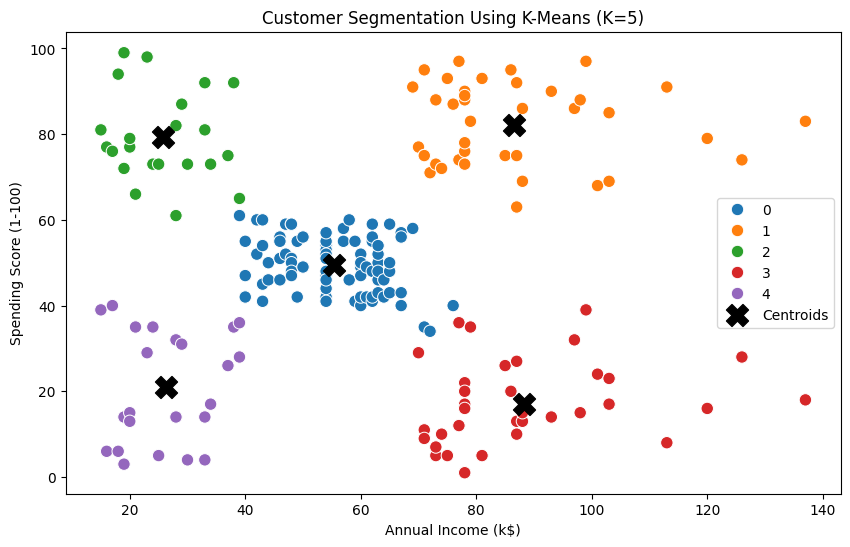

In [30]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(x_scaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=80,
    hue_order=sorted(df["Cluster"].unique())
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("Customer Segmentation Using K-Means (K=5)")
plt.legend()
plt.show()

In [31]:
print(df.groupby("Cluster")[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2))

print("\nCustomers per cluster:")
print(df["Cluster"].value_counts().sort_index())

           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        42.72               55.30                   49.52
1        32.69               86.54                   82.13
2        25.27               25.73                   79.36
3        41.11               88.20                   17.11
4        45.22               26.30                   20.91

Customers per cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
